In [81]:
#导入库
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams

rcParams['font.sans-serif'] = ['Microsoft YaHei']

In [82]:
#读取数据
df = pd.read_csv('data/air_quality_2023_daily.csv', parse_dates=['日期'])
df.head()

,城市,日期,月份,PM2.5,PM10,SO2,NO2,CO,O3,AQI,空气质量等级
0,上海,2023-01-01,1,140.9,212.8,136.3,127.2,2.244,1.3,187,中度污染
1,上海,2023-01-02,1,62.7,109.9,67.8,84.9,1.230,5.0,102,轻度污染
2,上海,2023-01-03,1,35.9,59.8,56.1,67.4,1.030,10.7,84,良
3,上海,2023-01-04,1,84.9,136.8,99.3,98.0,2.015,13.0,112,轻度污染
4,上海,2023-01-05,1,57.2,100.9,37.2,93.4,1.020,15.2,107,轻度污染


In [83]:
#转换数据类型
df['城市'] = df['城市'].astype('category')
df['空气质量等级'] = df['空气质量等级'].astype('category')

In [84]:
#查看缺失值
df.isna().sum()

城市        0
日期        0
月份        0
PM2.5     0
PM10      0
SO2       0
NO2       0
CO        0
O3        0
AQI       0
空气质量等级    0
dtype: int64

In [85]:
#查看异常值
columns = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'AQI']
for detect_value in columns:
    Q1 = df[detect_value].quantile(0.25)
    Q3 = df[detect_value].quantile(0.75)
    IQR = Q3 - Q1
    lowest = Q1 - 1.5 * IQR
    highest = Q3 + 1.5 * IQR
    Outlier = df[(df[detect_value] < lowest)&(df[detect_value] > highest)]
    if len(Outlier) > 0:
        print(detect_value,'的异常值如下')
        print(Outlier)
    else:
        print(detect_value,'无异常值')
    print('='*50)

PM2.5 无异常值
PM10 无异常值
SO2 无异常值
NO2 无异常值
CO 无异常值
O3 无异常值
AQI 无异常值


In [86]:
#描述性统计：分城市、分月份、分等级给出基本统计量；
df.groupby(['城市']).agg({
    'PM2.5': ['mean','max','min'],
    'PM10': ['mean','max','min'],
    'SO2': ['mean','max','min'],
    'NO2': ['mean','max','min'],
    'CO': ['mean','max','min'],
    'O3': ['mean','max','min'],
    'AQI': ['mean','max','min']
})

PM2.5                     PM10                     SO2               \
           mean    max   min        mean    max   min       mean    max   min   
城市                                                                              
上海    47.782740  310.6  11.3   72.720822  444.5  17.8  69.020274  363.5   5.0   
乌鲁木齐  55.601096  247.7  12.0  153.202466  719.0  22.5  14.920548   76.7   3.6   
北京    72.650137  259.1  10.3  107.098356  376.4  14.8  64.924384  227.3   9.2   
广州    41.694795  112.0  11.1   61.218082  162.0  16.6  52.230959  158.4  11.7   
成都    58.240000  131.5  20.3   84.825479  189.1  29.1  57.407123  182.7  19.2   
西安    51.463288  165.3  15.1   76.659452  236.4  22.5  42.055068  156.7   9.5   

            NO2  ...              CO                        O3              \
           mean  ...   min      mean     max    min       mean    max  min   
城市               ...                                                         
上海    68.109589  ...  21.2  1.045518  10.581  0.120  28.363562  105.5  0.0   
乌鲁木齐  42.109041  ...   5.7  0.472726   2.051  0.151  50.192603  116.9  5.7   
北京    64.522740  ...  21.8  1.279797   6.997  0.210  34.660548  137.6  0.6   
广州    58.624110  ...  16.6  0.790282   3.456  0.220  37.598630  117.0  1.1   
成都    52.813973  ...  21.2  0.933214   4.116  0.326  51.835890  170.3  7.2   
西安    54.415616  ...  19.2  0.898997   5.272  0.193  46.729863  150.2  4.3   

             AQI           
            mean  max min  
城市                         
上海     89.263014  361  26  
乌鲁木齐  123.523288  619  30  
北京    106.186301  309  27  
广州     78.295890  158  27  
成都     90.838356  205  31  
西安     90.769863  215  29  

[6 rows x 21 columns]

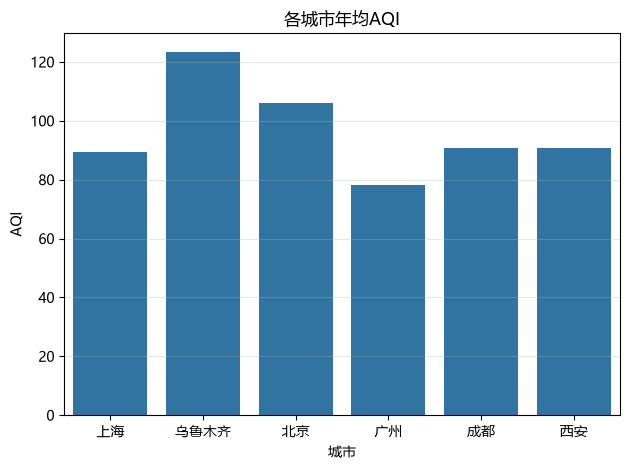

In [87]:
#各城市年均 AQI 对比
city_aqi = df[['城市','AQI']].groupby(['城市']).mean()
sns.barplot(data = city_aqi, x = '城市', y = 'AQI')
plt.title('各城市年均AQI')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

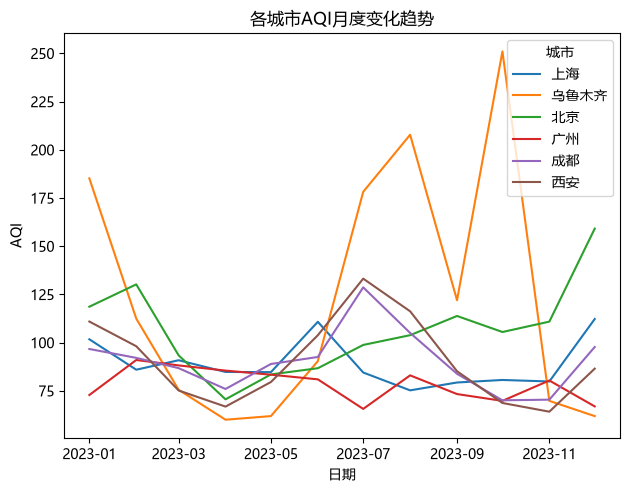

In [88]:
#PM2.5（或 AQI）月度变化趋势
city_aqi = df.groupby('城市')[['日期', 'AQI']].resample(rule = 'MS', on = '日期')[['AQI']].mean()
sns.lineplot(data = city_aqi, x = '日期', y = 'AQI', hue = '城市')
plt.tight_layout()
plt.title('各城市AQI月度变化趋势')
plt.show()

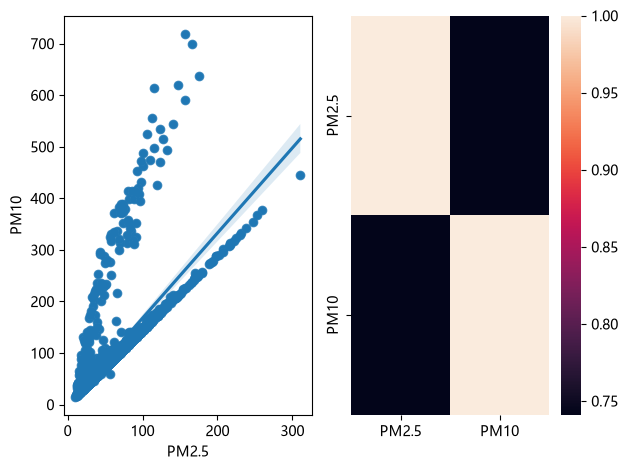

In [89]:
#PM2.5 与 PM10 相关性；
cor = df[['PM2.5','PM10']].corr()
plt.subplot(121)
sns.scatterplot(data = df, x = 'PM2.5', y = 'PM10')
sns.regplot(data = df, x = 'PM2.5', y = 'PM10')
plt.subplot(122)
sns.heatmap(cor)
plt.tight_layout()
plt.show()

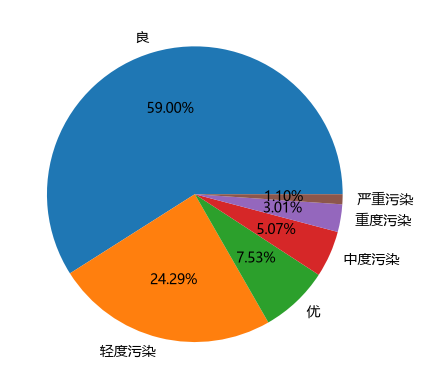

空气质量等级
良       1292
轻度污染     532
优        165
中度污染     111
重度污染      66
严重污染      24
Name: count, dtype: int64

In [90]:
#空气质量等级分布
Air_Quality_Level = df['空气质量等级'].value_counts()
plt.pie(x= Air_Quality_Level,
        labels = Air_Quality_Level.index,
        autopct= '%.2f%%'
        )
plt.tight_layout
plt.show()
df['空气质量等级'].value_counts()

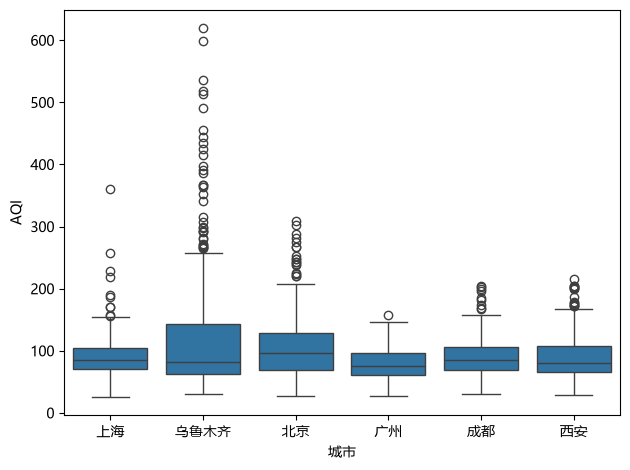

In [91]:
#各城市 AQI 分布特征
sns.boxplot(data = df, x = '城市', y = 'AQI')
plt.tight_layout()
plt.show()

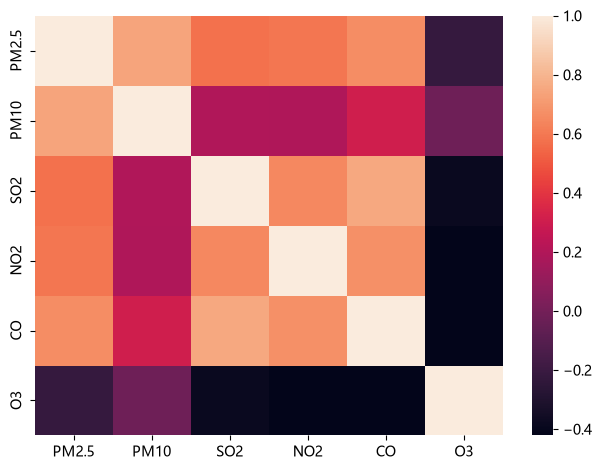

In [92]:
#污染物相关系数矩阵
pollutants = df.columns[3:-2]
pollutants_cor = df[pollutants].corr()
sns.heatmap(pollutants_cor)
plt.tight_layout()
plt.show()

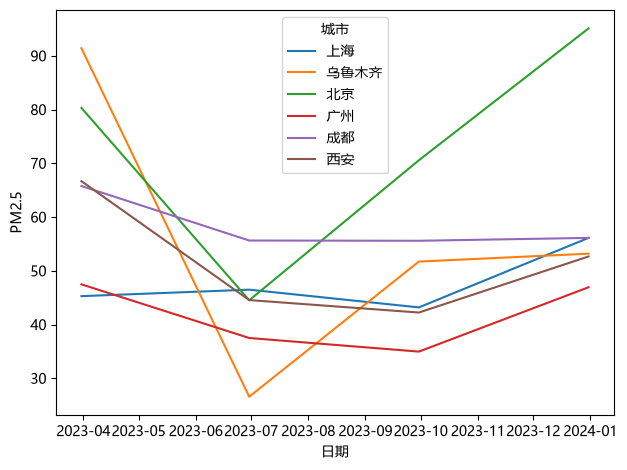

In [93]:
#季节变化规律
season_pm25 = df.groupby('城市')[['日期', 'PM2.5']].resample('QE', on = '日期').mean()
sns.lineplot(data = season_pm25, x = '日期', y = 'PM2.5', hue = '城市')
plt.tight_layout()
plt.show()